# 01 — Dataset Exploration

**Project:** EEG Attention State Detection (Deep Learning)
**Dataset:** [EEG Data for Mental Attention State Detection](https://www.kaggle.com/datasets/inancigdem/eeg-data-for-mental-attention-state-detection) (Kaggle, via KaggleHub)

### Goal of this notebook

This notebook is **exploration only**. We do **not** filter, normalize, segment, or build any model here.

We want to answer, in order:

1. How many *unique* recordings do we actually have (watch out for the duplicated `EEG Data/EEG Data/` folder)?
2. What is the internal MATLAB structure of each `.mat` file?
3. How many EEG channels, what sampling frequency, how many samples per recording?
4. How are attention labels (`Focused` / `Unfocused` / `Drowsy`) represented — in `tag`, `marker`, or `trials`?
5. Do multiple recordings belong to the same subject/session? (This determines how we must split train/test later.)
6. What does the raw EEG actually look like?

Everything downstream (`src/data/loader.py`, preprocessing, segmentation, modeling) depends on getting honest answers here — so we avoid assuming anything about the structure before we've actually printed it.


## 0. Imports


In [13]:
from pathlib import Path
from pprint import pprint

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (14, 4)


## 1. Locate the dataset

The dataset was downloaded via `kagglehub`, which caches it locally. We point directly at the cache rather than
copying 557 MB into `data/raw/` (see project notes — `data/raw/` stays out of Git for now).


In [14]:
DATASET_PATH = Path(
    r"C:\Users\gaida\.cache\kagglehub\datasets\inancigdem\eeg-data-for-mental-attention-state-detection\versions\1"
)

# NOTE: the archive contains a nested duplicate:
#   EEG Data/eeg_record*.mat            <- top-level copy
#   EEG Data/EEG Data/eeg_record*.mat   <- nested copy (identical files)
# Using rglob('*.mat') naively returns 68 files (34 x 2). We deliberately
# point at the deepest 'EEG Data/EEG Data' folder to get exactly 34 unique recordings.
EEG_DIR = DATASET_PATH / "EEG Data" / "EEG Data"

mat_files = sorted(EEG_DIR.glob("*.mat"))

print(f"Number of unique recordings found: {len(mat_files)}")
print("\nFirst 5 files:")
for f in mat_files[:5]:
    print(" ", f.name)

assert len(mat_files) == 34, "Expected exactly 34 unique recordings — check EEG_DIR path."


Number of unique recordings found: 34

First 5 files:
  eeg_record1.mat
  eeg_record10.mat
  eeg_record11.mat
  eeg_record12.mat
  eeg_record13.mat


## 2. Load one recording and inspect the top-level MATLAB variables

Before assuming anything about labels or channels, we look at exactly what keys `scipy.io.loadmat` gives us.


In [15]:
file_path = mat_files[0]
data = sio.loadmat(file_path)

print("File:", file_path.name)
print("\nVariables inside the MATLAB file:")
for key, value in data.items():
    if not key.startswith("__"):
        print(
            f"{key}: "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}, "
            f"dtype={getattr(value, 'dtype', None)}"
        )


File: eeg_record1.mat

Variables inside the MATLAB file:
o: type=<class 'numpy.ndarray'>, shape=(1, 1), dtype=[('id', 'O'), ('tag', 'O'), ('nS', 'O'), ('sampFreq', 'O'), ('marker', 'O'), ('timestamp', 'O'), ('data', 'O'), ('trials', 'O')]


## 3. Unpack the `o` struct and list its fields

The single variable of interest is `o`, a `(1, 1)` MATLAB struct. We pull out `o[0, 0]` and list its named fields
instead of guessing what's inside.


In [16]:
o = data["o"][0, 0]

print("Fields in `o`:")
pprint(o.dtype.names)

for field in o.dtype.names:
    value = o[field]
    print("\n" + "=" * 70)
    print(f"FIELD: {field}")
    print(f"Type:  {type(value)}")
    print(f"Shape: {getattr(value, 'shape', None)}")
    print(f"Dtype: {getattr(value, 'dtype', None)}")


Fields in `o`:
('id', 'tag', 'nS', 'sampFreq', 'marker', 'timestamp', 'data', 'trials')

FIELD: id
Type:  <class 'numpy.ndarray'>
Shape: (1,)
Dtype: <U21

FIELD: tag
Type:  <class 'numpy.ndarray'>
Shape: (0,)
Dtype: <U1

FIELD: nS
Type:  <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: int32

FIELD: sampFreq
Type:  <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: uint8

FIELD: marker
Type:  <class 'numpy.ndarray'>
Shape: (308868, 1)
Dtype: uint8

FIELD: timestamp
Type:  <class 'numpy.ndarray'>
Shape: (308868, 6)
Dtype: float64

FIELD: data
Type:  <class 'numpy.ndarray'>
Shape: (308868, 25)
Dtype: float64

FIELD: trials
Type:  <class 'numpy.ndarray'>
Shape: (1, 2, 14, 128)
Dtype: float64


## 4. Inspect the metadata fields individually

`id`, `tag`, `nS`, `sampFreq`, and `marker` are small enough to print directly. This is how we'll discover whether
`tag` already encodes `Focused` / `Unfocused` / `Drowsy`, or whether the labels live somewhere else (`marker`,
`trials`).


In [17]:
for field in ["id", "tag", "nS", "sampFreq", "marker"]:
    value = o[field]
    print("\n" + "=" * 70)
    print(field)
    print(value)



id
['201410092013.D091BB44']

tag
[]

nS
[[308868]]

sampFreq
[[128]]

marker
[[0]
 [0]
 [0]
 ...
 [0]
 [0]
 [0]]


In [9]:
print("DATA")
print("Shape:", o["data"].shape)
print("Dtype:", o["data"].dtype)

print("\nTRIALS")
print("Shape:", o["trials"].shape)
print("Dtype:", o["trials"].dtype)


DATA
Shape: (308868, 25)
Dtype: float64

TRIALS
Shape: (1, 2, 14, 128)
Dtype: float64


## 5. Resolve channels, sampling frequency, and duration for this recording

We deliberately compute these *from the file itself* rather than hard-coding assumed values (e.g. "25 channels,
128 Hz") — the actual numbers may differ.


In [18]:
fs = float(np.squeeze(o["sampFreq"]))
eeg = np.asarray(o["data"])

# `data` may come back as (n_samples, n_channels) or (n_channels, n_samples) depending on how
# MATLAB stored it — we check the shape rather than assuming an orientation.
print("Sampling frequency (Hz):", fs)
print("Raw data shape:", eeg.shape)

n_rows, n_cols = eeg.shape
if n_rows < n_cols:
    n_channels, n_samples = n_rows, n_cols
    eeg_ch_by_time = eeg
else:
    n_channels, n_samples = n_cols, n_rows
    eeg_ch_by_time = eeg.T

duration_sec = n_samples / fs

print(f"\nInferred number of channels: {n_channels}")
print(f"Inferred number of samples:  {n_samples}")
print(f"Recording duration: {duration_sec:.1f} s (~{duration_sec/60:.1f} min)")


Sampling frequency (Hz): 128.0
Raw data shape: (308868, 25)

Inferred number of channels: 25
Inferred number of samples:  308868
Recording duration: 2413.0 s (~40.2 min)


## 6. Visualize the raw EEG

### 6.1 First 10 seconds, all channels stacked (offset for readability)


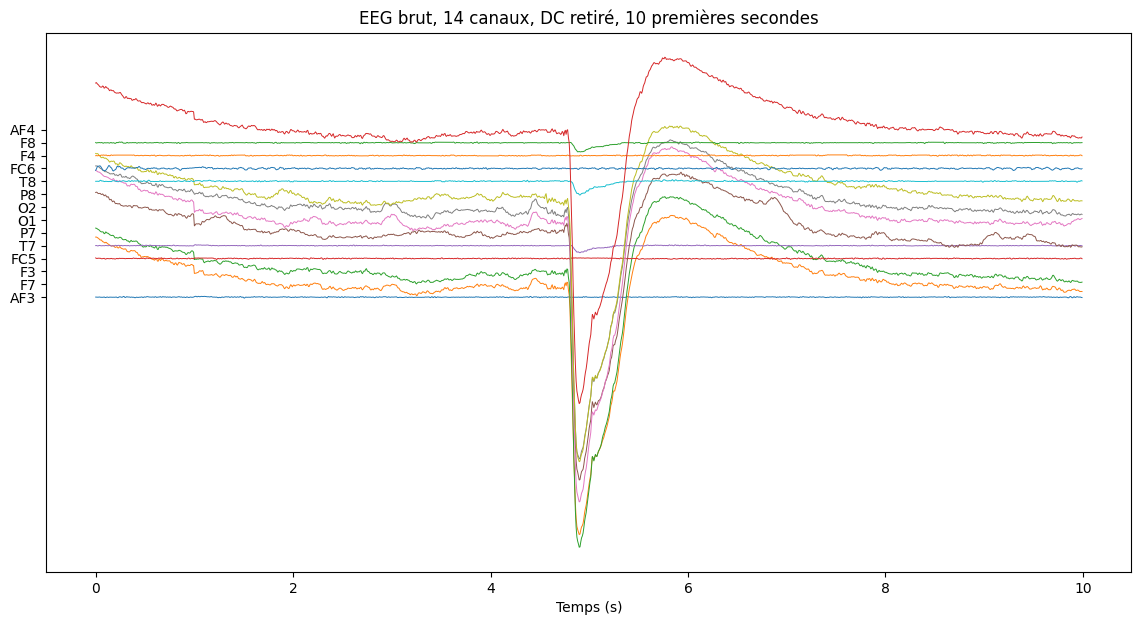

In [19]:
EEG_COLS = slice(3, 17)   # colonnes 4 à 17 (1-indexé) : hypothèse à vérifier
names = ["AF3","F7","F3","FC5","T7","P7","O1","O2","P8","T8","FC6","F4","F8","AF4"]

seg = eeg[:int(10 * fs), EEG_COLS]        # eeg = (n_samples, 25), tel que chargé
seg = seg - np.median(seg, axis=0)        # enlève l'offset DC (~4200)
step = 100                                # espacement fixe, à ajuster

t = np.arange(seg.shape[0]) / fs
fig, ax = plt.subplots(figsize=(14, 7))
for i in range(14):
    ax.plot(t, seg[:, i] + i * step, lw=0.7)
ax.set_yticks([i * step for i in range(14)])
ax.set_yticklabels(names)
ax.set_xlabel("Temps (s)")
ax.set_title("EEG brut, 14 canaux, DC retiré, 10 premières secondes")
plt.show()

### 6.2 Single channel, full recording


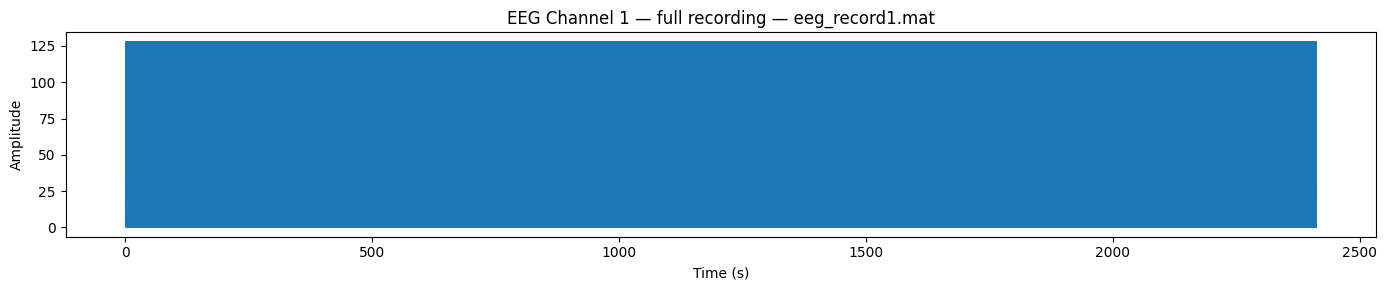

In [20]:
channel = 0  # 0-indexed; change to inspect other channels
t_full = np.arange(n_samples) / fs

plt.figure(figsize=(14, 3))
plt.plot(t_full, eeg_ch_by_time[channel], linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"EEG Channel {channel+1} — full recording — {file_path.name}")
plt.tight_layout()
plt.show()


### 6.3 Amplitude distribution per channel (sanity check for scale / outliers)


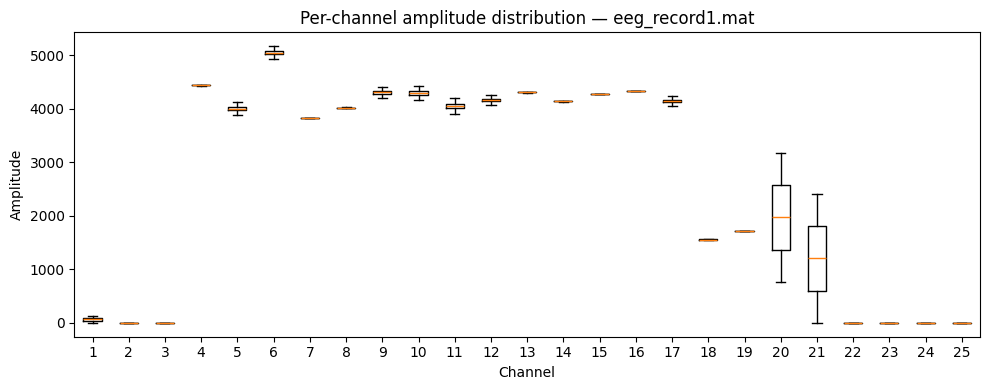

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([eeg_ch_by_time[ch] for ch in range(n_channels)], showfliers=False)
ax.set_xlabel("Channel")
ax.set_ylabel("Amplitude")
ax.set_title(f"Per-channel amplitude distribution — {file_path.name}")
plt.tight_layout()
plt.show()


## 7. Understand `marker` / `trials` (candidate label sources)

`tag` may or may not directly hold `Focused` / `Unfocused` / `Drowsy`. This cell prints `marker` and `trials` in a
more usable form (flattened arrays / value counts) so we can see if they look like event codes or segment
boundaries.


In [22]:
marker = np.squeeze(o["marker"])
trials = np.squeeze(o["trials"])

print("marker — shape:", np.shape(marker), " dtype:", getattr(marker, 'dtype', type(marker)))
print("trials — shape:", np.shape(trials), " dtype:", getattr(trials, 'dtype', type(trials)))

marker_flat = np.array(marker).ravel()
print("\nUnique marker values and counts:")
vals, counts = np.unique(marker_flat, return_counts=True)
for v, c in zip(vals, counts):
    print(f"  value={v!r:>10}  count={c}")


marker — shape: (308868,)  dtype: uint8
trials — shape: (2, 14, 128)  dtype: float64

Unique marker values and counts:
  value=np.uint8(0)  count=308640
  value=np.uint8(1)  count=228


## 8. Scan *all 34* recordings for consistency

A single file tells us the structure, but not whether it's consistent across the dataset. Here we loop over all
34 recordings and collect, for each: `id`, `tag`, sampling frequency, channel count, sample count, and duration.
This table is what we'll use to decide the subject/session grouping for train/test splitting.


In [23]:
def inspect_recording(path: Path) -> dict:
    raw = sio.loadmat(path)
    s = raw["o"][0, 0]

    fs_ = float(np.squeeze(s["sampFreq"]))
    arr = np.asarray(s["data"])
    r, c = arr.shape
    n_ch, n_samp = (r, c) if r < c else (c, r)

    def safe_str(x):
        x = np.squeeze(x)
        try:
            return str(x.item()) if x.size == 1 else str(x)
        except Exception:
            return str(x)

    return {
        "file": path.name,
        "id": safe_str(s["id"]),
        "tag": safe_str(s["tag"]),
        "sampFreq": fs_,
        "n_channels": n_ch,
        "n_samples": n_samp,
        "duration_sec": round(n_samp / fs_, 1),
    }

records = [inspect_recording(f) for f in mat_files]
df_summary = pd.DataFrame(records)
df_summary


,file,id,tag,sampFreq,n_channels,n_samples,duration_sec
0,eeg_record1.mat,201410092013.D091BB44,[],128.0,25,308868,2413.0
1,eeg_record10.mat,201412021859.D091BB44,[],128.0,25,381340,2979.2
2,eeg_record11.mat,201412031928.D091BB44,[],128.0,25,391624,3059.6
3,eeg_record12.mat,201412101811.D091BB44,[],128.0,25,356728,2786.9
4,eeg_record13.mat,201412111947.D091BB44,[],128.0,25,373304,2916.4
5,eeg_record14.mat,201412121958.D091BB44,[],128.0,25,345164,2696.6
6,eeg_record15.mat,201412171939.D091BB44,[],128.0,25,359164,2806.0
7,eeg_record16.mat,201412181945.D091BB44,[],128.0,25,234372,1831.0
8,eeg_record17.mat,201412191939.D091BB44,[],128.0,25,443972,3468.5
9,eeg_record18.mat,201412211957.D091BB44,[],128.0,25,361840,2826.9


### 8.1 Quick consistency checks

- Are `sampFreq` and `n_channels` identical across all recordings?
- Do `id` / `tag` values reveal a subject/session pattern (e.g. repeated subject IDs across several files)?


In [24]:
print("Unique sampling frequencies:", df_summary['sampFreq'].unique())
print("Unique channel counts:      ", df_summary['n_channels'].unique())
print("\nDuration stats (seconds):")
print(df_summary['duration_sec'].describe())

print("\nUnique `id` values:")
print(df_summary['id'].value_counts())

print("\nUnique `tag` values:")
print(df_summary['tag'].value_counts())


Unique sampling frequencies: [128.]
Unique channel counts:       [25]

Duration stats (seconds):
count      34.000000
mean     2875.126471
std       438.817468
min      1676.100000
25%      2718.050000
50%      2848.150000
75%      3089.975000
max      3779.200000
Name: duration_sec, dtype: float64

Unique `id` values:
id
201410092013.D091BB44    1
201412021859.D091BB44    1
201412031928.D091BB44    1
201412101811.D091BB44    1
201412111947.D091BB44    1
201412121958.D091BB44    1
201412171939.D091BB44    1
201412181945.D091BB44    1
201412191939.D091BB44    1
201412211957.D091BB44    1
201412231923.D091BB44    1
201410101933.D091BB44    1
201412251915.D091BB44    1
201412261901.D091BB44    1
201412281956.D091BB44    1
201501181956.D091BB44    1
201501201918.D091BB44    1
201501252000.D091BB44    1
201501271953.D091BB44    1
201502082013.D091BB44    1
201502141554.D091BB44    1
201502151624.D091BB44    1
201410121914.D091BB44    1
201502171657.2082353F    1
201502181626.D091BB44    1
2

In [25]:
# Save this summary — later steps (loader.py, subject-aware splitting) will read from it
OUTPUT_DIR = Path("../data/interim")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df_summary.to_csv(OUTPUT_DIR / "recording_summary.csv", index=False)
print(f"Saved summary to {OUTPUT_DIR / 'recording_summary.csv'}")


Saved summary to ..\data\interim\recording_summary.csv


## 9. What we know so far / open questions

Fill this in once the cells above have run against the real data — this is a template to record findings, not a
conclusion to assume in advance.

**Confirmed:**
- [ ] Number of unique recordings: `___`
- [ ] EEG channels per recording: `___`
- [ ] Sampling frequency: `___ Hz`
- [ ] Recording duration range: `___`
- [ ] Where the attention label actually lives (`tag` / `marker` / `trials`): `___`
- [ ] Whether `id` groups multiple recordings under the same subject: `___`

**Do NOT proceed to preprocessing/CNNs until the above is filled in with real values from the dataset.**

Next notebook: `02_label_and_subject_mapping.ipynb` — figure out the exact label encoding and build the
subject/session grouping table needed for a leakage-free train/test split.
